# Get a cut out from a Mining with MeerKAT EDR image

This notebook directly downloads a Mining with MeerKAT EDR image and makes a cut out around a radio galaxy.

In [88]:
import astropy.table as atpy
from astropy.io import fits
from astLib import astWCS, astImages
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import ImageNormalize, PercentileInterval, AsinhStretch
%matplotlib inline

In [89]:
# For loading stuff directly from where the EDR is served - set the base data release URL here
EDR_URL="https://extragalactic.phys.wits.ac.za/mining-with-meerkat/EDR/data/" # trailing slash is important

In [90]:
# Loading the images table, which gives info on each MeerKAT obseravtion included in the EDR
MKPointingsTab=atpy.Table().read(EDR_URL+"images_EDR.fits")

In [91]:
# Target coords and cut out size
RADeg=349.3856494
decDeg=0.1750374
sizeArcmin=4

# Set the URL for directly fetching a FITS image. A capture block can contain several pointings
# (one image each), so choose the image in this capture block whose centre is nearest the target
captureBlockId="1672735587"
cbTab=MKPointingsTab[MKPointingsTab['captureBlockId'] == captureBlockId]
from astropy.coordinates import SkyCoord
sepDeg=SkyCoord(cbTab['centre_RADeg'], cbTab['centre_decDeg'], unit="deg").separation(SkyCoord(RADeg, decDeg, unit="deg")).deg
imgRow=cbTab[sepDeg.argmin()]
imgURL=EDR_URL+imgRow['path']
print("Image: %s (centre %.2f deg from target)" % (imgRow['object'], sepDeg.min()))
print("Image URL: %s" % (imgURL))

Image: NGC7603 (centre 0.36 deg from target)
Image URL: https://extragalactic.phys.wits.ac.za/mining-with-meerkat/EDR/data/images/pbcorr_trim_img_1672735587_sdp_l0_1024ch_NGC7603.ms_pcalmask-MFS-image.fits


In [92]:
hdu=fits.open(imgURL)[0]
wcs=astWCS.WCS(hdu.header, mode = 'pyfits')
data=hdu.data.squeeze()                # drop degenerate freq/Stokes axes

In [93]:
# Cut out around the target coords
clip=astImages.clipImageSectionWCS(data, wcs, RADeg, decDeg, sizeArcmin/60)

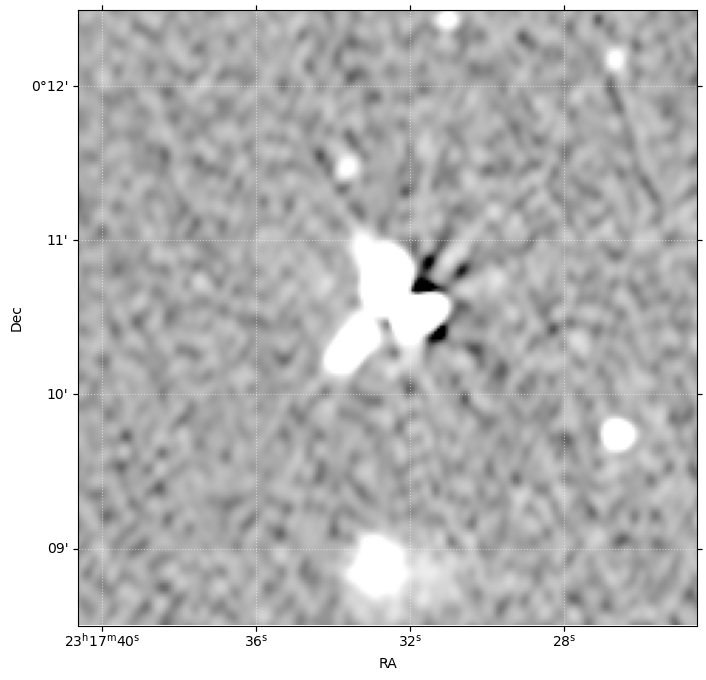

In [94]:
# Plot
%matplotlib inline
norm = ImageNormalize(data, interval=PercentileInterval(99.5), stretch=AsinhStretch())
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection=clip['wcs'].AWCS)
im = ax.imshow(clip['data'], origin="lower", cmap="gray", norm=norm)
ax.coords.grid(color="white", ls=":", alpha=0.5)
ax.set_xlabel("RA")
ax.set_ylabel("Dec")
# fig.colorbar(im, ax=ax, label=hdu.header.get("BUNIT", ""))
plt.show()

## LSST DP2 colour image of the same region

Fetches DP2 `deep_coadd` cutouts in z, r and g at the same position (`RADeg`, `decDeg`) and size (`sizeArcmin`) as the MeerKAT cutout above, and combines them into an RGB = (z, r, g) image.

The coadds are found through the RSP ObsCore table, and the cutouts come from the RSP image cutout (SODA) service. A coadd is divided into tracts, and each tract into overlapping patches. The cutout can straddle patch boundaries, so for each band the pieces from every overlapping patch in the best tract are stitched onto that tract's common pixel grid. If the field has no DP2 coadds, the section says so and stops.

In [95]:
import io
import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization import make_lupton_rgb
from astropy.wcs.utils import proj_plane_pixel_scales
from pyvo.dal.adhoc import DatalinkResults, SodaQuery
from lsst.rsp import get_tap_service
from lsst.rsp.utils import get_pyvo_auth

RGB_BANDS = ("z", "r", "g")   # (R, G, B)
RGB_SCALES = (0.5, 0.9, 1.6)  # per-band flux multipliers for colour balance (z is brightest in nJy)
RGB_STRETCH, RGB_Q = 30, 6    # make_lupton_rgb parameters

In [96]:
def findDP2Coadds(RADeg, decDeg, sizeArcmin, bands=RGB_BANDS):
    """Return the DP2 deep_coadd ObsCore rows (one tract only) overlapping a sizeArcmin box around RADeg, decDeg."""
    # The TAP service does not support INTERSECTS, so find every patch containing any point of a grid
    # (spacing <= 3 arcmin, much smaller than a patch) covering the box
    nGrid = int(np.ceil(sizeArcmin / 3)) + 1
    offsets = np.linspace(-sizeArcmin / 2, sizeArcmin / 2, nGrid) / 60
    cosDec = np.cos(np.radians(decDeg))
    points = [(RADeg + dx / cosDec, decDeg + dy) for dx in offsets for dy in offsets]
    contains = " OR ".join(f"CONTAINS(POINT('ICRS', {ra % 360:.6f}, {dec:.6f}), s_region) = 1" for ra, dec in points)
    bandList = ", ".join(f"'{b}'" for b in bands)
    query = f"""SELECT DISTINCT lsst_band, lsst_tract, lsst_patch, s_ra, s_dec, access_url
                FROM ivoa.ObsCore
                WHERE obs_collection = 'LSST.DP2' AND dataproduct_subtype = 'lsst.deep_coadd'
                AND lsst_band IN ({bandList}) AND ({contains})"""
    tab = get_tap_service("tap").search(query).to_table()
    if len(tab) == 0:
        return tab
    # Patches from different tracts are on different pixel grids, so use only the tract whose
    # nearest patch centre is closest to the target
    sep = SkyCoord(tab["s_ra"], tab["s_dec"], unit="deg").separation(SkyCoord(RADeg, decDeg, unit="deg"))
    return tab[tab["lsst_tract"] == tab["lsst_tract"][np.argmin(sep)]]


def fetchCutout(accessURL, RADeg, decDeg, sizeArcmin):
    """Fetch a cutout from one coadd via the SODA service. Returns the IMAGE HDU."""
    auth = get_pyvo_auth()
    dl = DatalinkResults.from_result_url(accessURL, session=auth)
    sq = SodaQuery.from_resource(dl, dl.get_adhocservice_by_id("cutout-sync"), session=auth)
    sq.circle = (RADeg * u.deg, decDeg * u.deg, (sizeArcmin / 60 / 2) * u.deg)   # returns the bounding square
    return fits.open(io.BytesIO(sq.execute_stream().read()))["IMAGE"]


def stitchCutouts(hdus, RADeg, decDeg, sizeArcmin):
    """Put cutouts from patches of the same tract onto one sizeArcmin x sizeArcmin array.

    Uses the alternate 'A' WCS in each cutout header, which gives the position on the tract pixel grid.
    Returns (data, wcs). Pixels with no coverage are NaN.
    """
    ref = hdus[0].header
    refWCS = WCS(ref)
    pixScaleArcsec = proj_plane_pixel_scales(refWCS)[0] * 3600
    n = int(round(sizeArcmin * 60 / pixScaleArcsec)) + 1
    tractOrigin = lambda h: (int(h["CRVAL1A"] - h["CRPIX1A"]) + 1, int(h["CRVAL2A"] - h["CRPIX2A"]) + 1)
    rx0, ry0 = tractOrigin(ref)
    px, py = refWCS.world_to_pixel_values(RADeg, decDeg)
    ox, oy = rx0 + int(round(float(px))) - n // 2, ry0 + int(round(float(py))) - n // 2   # output origin, tract pixels

    out = np.full((n, n), np.nan, dtype=np.float32)
    for h in hdus:
        x0, y0 = tractOrigin(h.header)
        ny, nx = h.data.shape
        xa, xb = max(x0, ox), min(x0 + nx, ox + n)
        ya, yb = max(y0, oy), min(y0 + ny, oy + n)
        if xa >= xb or ya >= yb:
            continue
        dst = out[ya - oy:yb - oy, xa - ox:xb - ox]
        src = h.data[ya - y0:yb - y0, xa - x0:xb - x0]
        fill = np.isnan(dst)
        dst[fill] = src[fill]

    outWCS = refWCS.deepcopy()
    outWCS.wcs.crpix = refWCS.wcs.crpix - np.array([ox - rx0, oy - ry0])
    return out, outWCS

In [97]:
coaddTab = findDP2Coadds(RADeg, decDeg, sizeArcmin)
missing = [b for b in RGB_BANDS if b not in coaddTab["lsst_band"]] if len(coaddTab) else list(RGB_BANDS)
if missing:
    print(f"No DP2 deep_coadd at RA, dec = {RADeg:.5f}, {decDeg:.5f} in band(s) {missing}: no colour image for this field.")
else:
    print(f"Tract {coaddTab['lsst_tract'][0]}, patches {sorted(set(coaddTab['lsst_patch']))}")
    lsstImages = {}
    for band in RGB_BANDS:
        rows = coaddTab[coaddTab["lsst_band"] == band]
        hdus = [fetchCutout(row["access_url"], RADeg, decDeg, sizeArcmin) for row in rows]
        lsstImages[band], lsstWCS = stitchCutouts(hdus, RADeg, decDeg, sizeArcmin)
        print(f"{band}: {len(hdus)} patch(es), {np.isfinite(lsstImages[band]).mean():.0%} of cutout covered")

Tract 9705, patches [np.int64(16)]
z: 1 patch(es), 100% of cutout covered
r: 1 patch(es), 100% of cutout covered
g: 1 patch(es), 100% of cutout covered


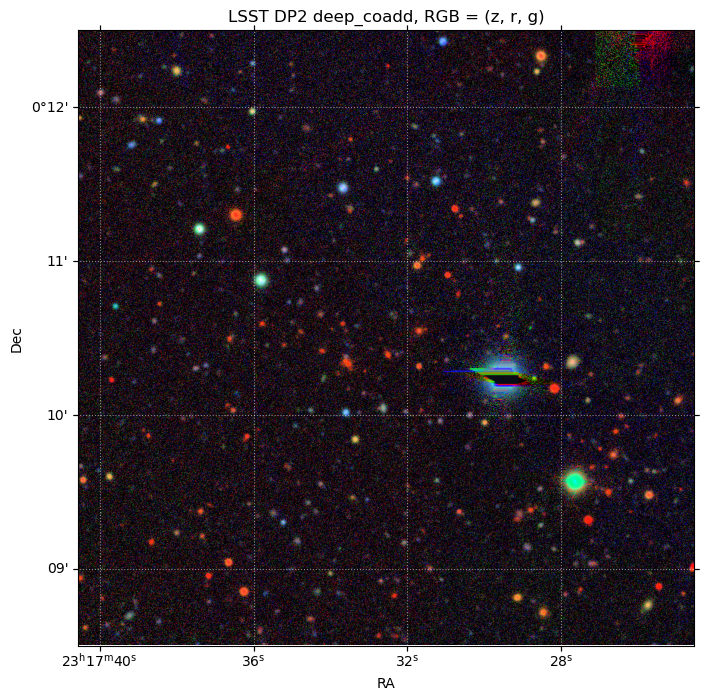

In [98]:
# RGB = (z, r, g), Lupton et al. (2004) asinh stretch. Images are in nJy; adjust RGB_SCALES / RGB_STRETCH / RGB_Q to taste.
if not missing:
    rgb = make_lupton_rgb(*[np.nan_to_num(lsstImages[b]) * s for b, s in zip(RGB_BANDS, RGB_SCALES)],
                          stretch=RGB_STRETCH, Q=RGB_Q, minimum=0)
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection=lsstWCS)
    ax.imshow(rgb, origin="lower")
    ax.coords.grid(color="white", ls=":", alpha=0.5)
    ax.set_xlabel("RA")
    ax.set_ylabel("Dec")
    ax.set_title(f"LSST DP2 deep_coadd, RGB = ({', '.join(RGB_BANDS)})")
    plt.show()

## MeerKAT radio contours over the DP2 colour image

The MeerKAT cutout (`clip`) is drawn as contours over the DP2 RGB image. Contour levels are multiples of the local RMS: a 3σ-clipped standard deviation of the cutout itself. That is used instead of the whole-image value in `images_EDR.fits` (`RMS_uJy/beam`, also printed), because the noise in primary-beam-corrected images rises with distance from the pointing centre. The contours are drawn using the MeerKAT image's own WCS (via `transform`), so the radio image doesn't need regridding onto the optical pixel grid.

In [99]:
from astropy.stats import sigma_clipped_stats

CONTOUR_SIGMA_LEVELS = [3, 5, 10, 20, 40, 80, 160]   # contour levels in units of the local RMS
CONTOUR_COLOUR = "cyan"

radioData = clip['data']   # Jy/beam
radioWCS = clip['wcs'].AWCS.celestial
tableRMS = imgRow['RMS_uJy/beam'] * 1e-6   # whole-image RMS from images_EDR.fits, uJy/beam -> Jy/beam
_, _, localRMS = sigma_clipped_stats(radioData, sigma=3, maxiters=10)
print("Local 3-sigma-clipped RMS of this cutout (used for contours): %.2f uJy/beam" % (localRMS * 1e6))
print("Image RMS from images_EDR.fits, for comparison: %.2f uJy/beam" % (tableRMS * 1e6))
radioRMS = localRMS
contourLevels = np.array(CONTOUR_SIGMA_LEVELS) * radioRMS

Local 3-sigma-clipped RMS of this cutout (used for contours): 19.19 uJy/beam
Image RMS from images_EDR.fits, for comparison: 14.30 uJy/beam


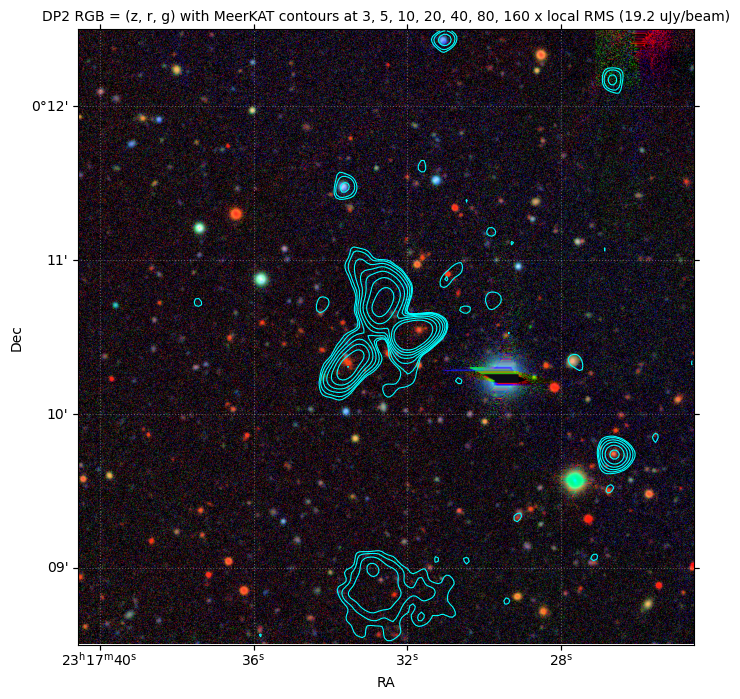

In [100]:
if missing:
    print("No DP2 colour image for this field (see above), so no overlay.")
else:
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(projection=lsstWCS)
    ax.imshow(rgb, origin="lower")
    ax.set_autoscale_on(False)   # keep the optical image extent
    ax.contour(radioData, levels=contourLevels, colors=CONTOUR_COLOUR, linewidths=0.8,
               transform=ax.get_transform(radioWCS))
    ax.coords.grid(color="white", ls=":", alpha=0.3)
    ax.set_xlabel("RA")
    ax.set_ylabel("Dec")
    ax.set_title("DP2 RGB = (%s) with MeerKAT contours at %s x local RMS (%.1f uJy/beam)"
                 % (", ".join(RGB_BANDS), ", ".join(str(s) for s in CONTOUR_SIGMA_LEVELS), radioRMS * 1e6),
                 fontsize="medium")
    plt.show()